# 05 · Portfolio Construction at Scale & Quantum-Ready Fund Selection

Two problems an allocator faces when building portfolios *from funds*:

**A. Robust construction.** With hundreds of candidate funds and only a few years of monthly data,
the sample covariance matrix is noisy or even singular. Optimisers exploit that noise. A walk-forward
test (annual rebalancing, 2011–2025) compares equal weight, sample and shrinkage minimum-variance,
equal risk contribution, and a fee-aware alpha tilt, all solved with `cvxpy`, on what was *realised*
out of sample.

**B. Cardinality-constrained replication.** "Replicate this portfolio with exactly K low-cost ETFs" is
a combinatorial problem (choose K of n) that convex solvers cannot handle directly. It maps naturally to
a **QUBO** (quadratic unconstrained binary optimisation), the native format of quantum annealers
and QAOA. A classical simulated annealer solves it here, verified against brute force and benchmarked
against greedy selection, with an export to D-Wave's `dimod` format.

A short section in between shows the vectorised analytics behind running such computations for
hundreds of thousands of advisor portfolios.

In [1]:
import sys, time, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cvxpy as cp
from pfquant import make_universe, make_advisor_holdings, stats, plotting, qubo
plotting.setup()
pd.set_option("display.float_format", "{:.3f}".format)

USE_REAL_DATA = False
if USE_REAL_DATA:
    from pfquant.real_data import load_real_universe
    uni = load_real_universe()
else:
    uni = make_universe()
R, F, funds = uni.fund_returns, uni.factor_returns, uni.funds

## A. Walk-forward portfolio construction

Each December: estimate on the trailing 60 months, optimise over all funds with complete history,
hold the weights (rebalanced monthly to target) for 12 months. Constraints: fully invested, long-only,
at most 10 % per fund. Returns are net of fund fees.

In [2]:
def min_variance(S, wmax=0.10):
    n = len(S); w = cp.Variable(n)
    prob = cp.Problem(cp.Minimize(cp.quad_form(w, cp.psd_wrap(S))), [cp.sum(w) == 1, w >= 0, w <= wmax])
    prob.solve(solver=cp.CLARABEL); return np.clip(w.value, 0, None) / np.clip(w.value, 0, None).sum()

def alpha_tilt(S, mu, gamma=5.0, wmax=0.10):
    n = len(S); w = cp.Variable(n)
    prob = cp.Problem(cp.Maximize(mu @ w - gamma * cp.quad_form(w, cp.psd_wrap(S))),
                      [cp.sum(w) == 1, w >= 0, w <= wmax])
    prob.solve(solver=cp.CLARABEL); return np.clip(w.value, 0, None) / np.clip(w.value, 0, None).sum()

def risk_parity(S):
    """Long-only equal risk contribution via Spinu's (2013) convex program:
    min ½ y'Sy − (1/n) Σ log y_i,  then w = y / Σy.  Well defined even when some
    funds hedge others (negative marginal risk), unlike naive fixed-point updates."""
    n = len(S); y = cp.Variable(n, pos=True)
    cp.Problem(cp.Minimize(0.5 * cp.quad_form(y, cp.psd_wrap(S)) - cp.sum(cp.log(y)) / n)).solve(solver=cp.CLARABEL)
    w = y.value / y.value.sum()
    rc = w * (S @ w)
    assert rc.max() / rc.min() < 1.01, "risk contributions not equalised"
    return w

def shrunk_alpha(X, Ff):
    a, se = np.empty(X.shape[1]), np.empty(X.shape[1])
    for j in range(X.shape[1]):
        _, al, res, _ = stats.rbsa(X[:, j], Ff)
        a[j] = al * 12; se[j] = (res.std() / np.sqrt(len(res))) * 12
    tau2 = max(np.var(a) - np.mean(se ** 2), 1e-8)
    return a * tau2 / (tau2 + se ** 2)

EST = 60
anchors = list(range(EST + 12 * 0, len(R) - 12 + 1, 12))
strategies = ["Equal weight", "Min-var (sample cov)", "Min-var (Ledoit–Wolf)", "Risk parity (LW)",
              "Min-var + shrunk-alpha tilt (LW)"]
rets = {s: [] for s in strategies}; diag = []
prev_w = {s: None for s in strategies}
for a in anchors:
    est, hold = slice(a - EST, a), slice(a, a + 12)
    ok = R.iloc[est].notna().all() & R.iloc[hold].notna().all()
    ids = R.columns[ok]
    X = R.iloc[est][ids].to_numpy()
    S_samp = np.cov(X.T); S_lw = stats.ledoit_wolf_cov(X)
    mu = shrunk_alpha(X, F.iloc[est].to_numpy())
    W = {
        "Equal weight": np.ones(len(ids)) / len(ids),
        "Min-var (sample cov)": min_variance(S_samp),
        "Min-var (Ledoit–Wolf)": min_variance(S_lw),
        "Risk parity (LW)": risk_parity(S_lw),
        "Min-var + shrunk-alpha tilt (LW)": alpha_tilt(S_lw * 12, mu),
    }
    Y = R.iloc[hold][ids].to_numpy()
    fee = funds.loc[ids, "expense_ratio"].to_numpy()
    for s, w in W.items():
        r = Y @ w
        rets[s].append(pd.Series(r, index=R.index[hold]))
        pred_vol = np.sqrt(w @ S_samp @ w * 12) if "sample" in s else np.sqrt(w @ S_lw @ w * 12)
        pw = prev_w[s]
        turnover = np.nan if pw is None else 0.5 * np.abs(w - pw.reindex(ids).fillna(0).to_numpy()).sum()
        diag.append(dict(date=R.index[a - 1], strategy=s, n_funds=len(ids), holdings=(w > 1e-4).sum(),
                         predicted_vol=pred_vol, realised_vol=r.std() * np.sqrt(12),
                         turnover=turnover, avg_fee=w @ fee))
        prev_w[s] = pd.Series(w, index=ids)
rets = {s: pd.concat(v) for s, v in rets.items()}
assert all(r.notna().all() for r in rets.values()), "missing strategy returns"
diag = pd.DataFrame(diag)
print(f"{len(anchors)} annual rebalances, {diag['n_funds'].min()}–{diag['n_funds'].max()} candidate funds each, "
      f"out-of-sample {rets['Equal weight'].index[0]:%Y-%m} to {rets['Equal weight'].index[-1]:%Y-%m}")

15 annual rebalances, 440–644 candidate funds each, out-of-sample 2011-01 to 2025-12


,Ann. return,Ann. volatility,Sharpe (rf=0),Max drawdown,avg # funds,avg annual turnover,avg fee,predicted / realised vol
Equal weight,7.28%,11.20%,0.68,-30.0%,543,3%,0.67%,1.17
Min-var (sample cov),3.59%,4.96%,0.74,-10.2%,19,32%,0.45%,0.98
Min-var (Ledoit–Wolf),3.68%,4.93%,0.76,-10.3%,37,25%,0.45%,0.96
Risk parity (LW),6.04%,8.01%,0.77,-22.6%,543,6%,0.61%,1.15
Min-var + shrunk-alpha tilt (LW),5.04%,5.94%,0.86,-15.1%,16,45%,0.66%,1.03


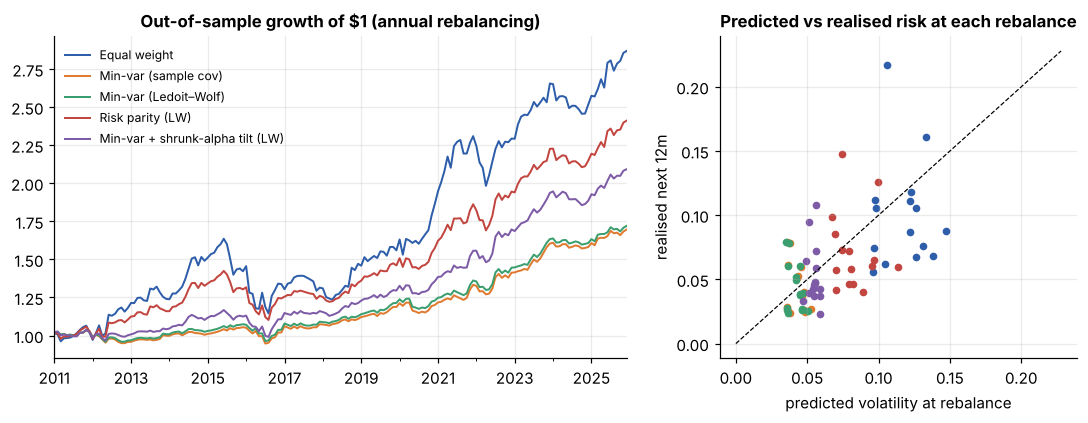

In [3]:
perf = pd.DataFrame({s: {"Ann. return": stats.ann_return(r), "Ann. volatility": stats.ann_vol(r),
                         "Sharpe (rf=0)": stats.sharpe(r), "Max drawdown": stats.max_drawdown(r)}
                     for s, r in rets.items()}).T
d = diag.groupby("strategy")[["holdings", "turnover", "avg_fee"]].mean()
d["predicted / realised vol"] = (diag.groupby("strategy")["predicted_vol"].mean() /
                                 diag.groupby("strategy")["realised_vol"].mean())
perf = perf.join(d.rename(columns={"holdings": "avg # funds", "turnover": "avg annual turnover", "avg_fee": "avg fee"}))
display(perf.loc[strategies].style.format({"Ann. return": "{:.2%}", "Ann. volatility": "{:.2%}", "Sharpe (rf=0)": "{:.2f}",
                                           "Max drawdown": "{:.1%}", "avg # funds": "{:.0f}",
                                           "avg annual turnover": "{:.0%}", "avg fee": "{:.2%}",
                                           "predicted / realised vol": "{:.2f}"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
for s in strategies:
    (1 + rets[s]).cumprod().plot(ax=axes[0], label=s, lw=1.3)
axes[0].set_title("Out-of-sample growth of $1 (annual rebalancing)"); axes[0].legend(fontsize=8); axes[0].set_xlabel("")
for s in strategies:
    g = diag[diag.strategy == s]
    axes[1].scatter(g["predicted_vol"], g["realised_vol"], s=16, label=s)
lim = [0, diag[["predicted_vol", "realised_vol"]].max().max() * 1.05]
axes[1].plot(lim, lim, "k--", lw=0.8)
axes[1].set_xlabel("predicted volatility at rebalance"); axes[1].set_ylabel("realised next 12m")
axes[1].set_title("Predicted vs realised risk at each rebalance")
plotting.save(fig, "05_walk_forward")

## Scale: analytics for every advisor book at once

Distribution intelligence means repeating these computations for every advisor portfolio. Written as
matrix algebra, the tracking error of *every* advisor book against *every* fund is two matrix products.
Here: 3,000 simulated books × 644 funds; the timing extrapolates linearly to 400,000 advisors.

In [4]:
advisors, holdings = make_advisor_holdings(uni)
X36 = R.iloc[-36:]; live = X36.columns[X36.notna().all()]
fidx = {f: i for i, f in enumerate(live)}
h = holdings[(holdings.quarter == "2025Q4") & holdings.fund_id.isin(live)]
A = np.zeros((len(advisors), len(live)))
np.add.at(A, (h.advisor_id.map({a: i for i, a in enumerate(advisors.index)}).values, h.fund_id.map(fidx).values), h.value.values)
A /= A.sum(1, keepdims=True)
C = stats.ledoit_wolf_cov(X36[live].to_numpy()) * 12
t0 = time.perf_counter()
cov_book_fund = A @ C                                           # book × fund covariances
var_book = (cov_book_fund * A).sum(1)                           # each book's variance
TE_all = np.sqrt(np.clip(var_book[:, None] + np.diag(C)[None, :] - 2 * cov_book_fund, 0, None))
dt = time.perf_counter() - t0
print(f"{TE_all.size:,} book-vs-fund tracking errors in {dt * 1000:.0f} ms "
      f"→ ≈{dt * 400_000 / len(advisors):.1f} s for 400,000 advisors on one CPU core")

1,932,000 book-vs-fund tracking errors in 69 ms → ≈9.2 s for 400,000 advisors on one CPU core


## B. Replicating a portfolio with exactly K ETFs: a QUBO

**Task.** An advisor's model portfolio (here: the largest book in the sample) should be rebuilt
from exactly *K* low-cost passive ETFs, equal-weighted for simplicity of implementation, to minimise
tracking error with a small fee penalty.

With binary $x_i$ (fund *i* selected) and weights $w = x/K$:

$$\min_x \; \tfrac{1}{K^2}x^\top \Sigma x - \tfrac{2}{K} c^\top x + \tfrac{\lambda}{K} f^\top x + A\,(\mathbf 1^\top x - K)^2$$

where $\Sigma$ is the candidates' covariance, $c$ their covariance with the target and $f$ their fees.
This is $x^\top Q x$: a QUBO with no constraints left. `pfquant.qubo` builds $Q$ and solves it by
simulated annealing with swap moves.

In [5]:
book = A[np.argmax(advisors["aum"].values)]
etfs = [f for f in live if funds.loc[f, "passive"] and funds.loc[f, "vehicle"] == "ETF"]
eidx = [fidx[f] for f in etfs]
S = C[np.ix_(eidx, eidx)]
c = C[eidx] @ book
var_t = book @ C @ book
fee = funds.loc[etfs, "expense_ratio"].to_numpy()
K, LAM = 6, 0.5
print(f"Target: advisor book with {(book > 0).sum()} funds, avg fee {book @ funds.loc[live, 'expense_ratio'].to_numpy():.2%}; "
      f"candidates: {len(etfs)} passive ETFs; choose K = {K}")

Q, const = qubo.build_qubo(S, c, K, fee=fee, lam_fee=LAM)
def te_of(x):
    w = x / x.sum()
    return np.sqrt(max(w @ S @ w - 2 * c @ w + var_t, 0))

t0 = time.perf_counter(); x_sa, e_sa = qubo.simulated_annealing(Q, K, n_sweeps=300, n_restarts=8, seed=0); t_sa = time.perf_counter() - t0
t0 = time.perf_counter(); x_gr, e_gr = qubo.greedy_select(Q, K); t_gr = time.perf_counter() - t0
rng = np.random.default_rng(0)
t0 = time.perf_counter()
rand = min((qubo.qubo_energy(Q, x), x) for x in (np.isin(np.arange(len(etfs)), rng.choice(len(etfs), K, replace=False)).astype(float)
                                                for _ in range(2000)))
t_rd = time.perf_counter() - t0
obj = lambda e: e + const + var_t                     # = TE² + fee penalty (the cardinality penalty is 0)
cmp_tab = pd.DataFrame({
    "objective (TE² + fee term), bp": [obj(e_sa) * 1e4, obj(e_gr) * 1e4, obj(rand[0]) * 1e4],
    "tracking error": [te_of(x_sa), te_of(x_gr), te_of(rand[1])],
    "avg fee": [fee @ x_sa / K, fee @ x_gr / K, fee @ rand[1] / K],
    "seconds": [t_sa, t_gr, t_rd]}, index=["Simulated annealing (QUBO)", "Greedy forward selection", "Best of 2,000 random"])
display(cmp_tab.style.format({"objective (TE² + fee term), bp": "{:.3f}", "tracking error": "{:.2%}", "avg fee": "{:.2%}", "seconds": "{:.2f}"}))
sel = pd.DataFrame({"category": funds.loc[np.array(etfs)[x_sa > 0], "category"],
                    "expense_ratio": funds.loc[np.array(etfs)[x_sa > 0], "expense_ratio"]})
sel

Target: advisor book with 25 funds, avg fee 0.62%; candidates: 158 passive ETFs; choose K = 6


,"objective (TE² + fee term), bp",tracking error,avg fee,seconds
Simulated annealing (QUBO),6.138,1.90%,0.05%,2.04
Greedy forward selection,6.625,2.04%,0.05%,0.02
"Best of 2,000 random",8.039,2.10%,0.07%,0.08


,category,expense_ratio
fund_id,,
F0022,Moderate Allocation,0.000
F0138,Intermediate Core Bond,0.001
F0192,US Large Blend,0.000
F0278,US Small Cap,0.001
F0284,Global Equity,0.000
F0368,Global Equity,0.000


### Is the annealer finding the optimum?

On smaller instances the exact optimum is available by brute force. Across 30 random instances
(24 candidates, K = 4, i.e. 10,626 combinations each), compare simulated annealing and greedy with the true optimum.

In [6]:
gaps = []
for seed in range(30):
    r = np.random.default_rng(100 + seed)
    sub = r.choice(len(etfs), 24, replace=False)
    Qs, _ = qubo.build_qubo(S[np.ix_(sub, sub)], c[sub], 4, fee=fee[sub], lam_fee=LAM)
    _, e_opt = qubo.brute_force(Qs, 4)
    _, e_s = qubo.simulated_annealing(Qs, 4, n_sweeps=150, n_restarts=4, seed=seed)
    _, e_g = qubo.greedy_select(Qs, 4)
    # energies carry a large constant from the penalty term, so compare with an absolute tolerance
    gaps.append(dict(sa_optimal=np.isclose(e_s, e_opt, rtol=0, atol=1e-10),
                     greedy_optimal=np.isclose(e_g, e_opt, rtol=0, atol=1e-10),
                     greedy_gap=e_g - e_opt, sa_gap=e_s - e_opt))
gaps = pd.DataFrame(gaps)
print(f"Simulated annealing hit the exact optimum in {gaps.sa_optimal.mean():.0%} of instances; "
      f"greedy in {gaps.greedy_optimal.mean():.0%} (mean greedy excess objective "
      f"{gaps.greedy_gap.mean() * 1e4:.3f} bp).")

Simulated annealing hit the exact optimum in 100% of instances; greedy in 30% (mean greedy excess objective 0.688 bp).


### Cardinality vs tracking error, and out-of-sample check

How many ETFs does the replication need? For each K the QUBO picks the funds; then `cvxpy` re-optimises
the weights on that subset (a convex problem once the subset is fixed). The out-of-sample column fits on
2020–2022 and measures tracking error over 2023–2025. That period was calmer than 2020–22, so out-of-sample
tracking errors are lower across the board; compare across K, not across columns.

,te_equal_weight,te_reoptimised,te_out_of_sample,avg_fee
K,,,,
2,3.72%,3.71%,2.02%,0.04%
3,3.26%,3.23%,1.92%,0.04%
4,2.97%,2.96%,1.82%,0.05%
6,2.47%,2.36%,1.16%,0.05%
8,2.28%,2.25%,1.14%,0.05%
12,2.02%,2.00%,1.14%,0.05%
16,1.87%,1.82%,1.05%,0.05%


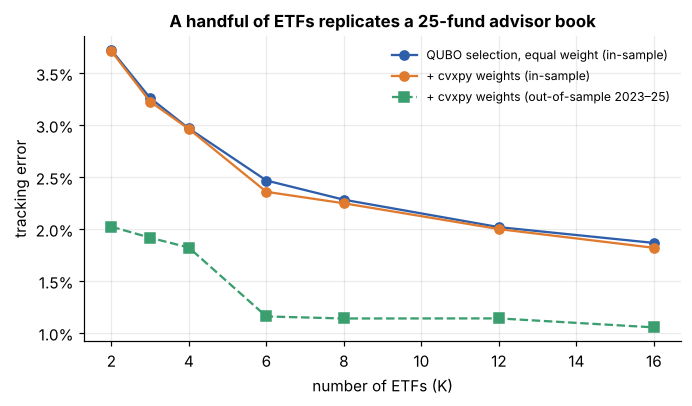

In [7]:
fit_idx, oos_idx = R.index[-72:-36], R.index[-36:]
Xf, Xo = R.loc[fit_idx, live].to_numpy(), R.loc[oos_idx, live].to_numpy()
Cf = stats.ledoit_wolf_cov(Xf) * 12
Sf, cf = Cf[np.ix_(eidx, eidx)], Cf[eidx] @ book
tgt_o = Xo @ book
rows = []
for K_ in [2, 3, 4, 6, 8, 12, 16]:
    Qk, _ = qubo.build_qubo(Sf, cf, K_, fee=fee, lam_fee=LAM)
    xk, _ = qubo.simulated_annealing(Qk, K_, n_sweeps=200, n_restarts=4, seed=K_)
    idx = np.flatnonzero(xk)
    w = cp.Variable(len(idx))
    obj = cp.quad_form(w, cp.psd_wrap(Sf[np.ix_(idx, idx)])) - 2 * cf[idx] @ w
    cp.Problem(cp.Minimize(obj), [cp.sum(w) == 1, w >= 0]).solve(solver=cp.CLARABEL)
    wv = np.clip(w.value, 0, None); wv /= wv.sum()
    te_eq = np.sqrt(max(xk @ Sf @ xk / K_**2 - 2 * cf @ xk / K_ + book @ Cf @ book, 0))
    te_opt = np.sqrt(max(wv @ Sf[np.ix_(idx, idx)] @ wv - 2 * cf[idx] @ wv + book @ Cf @ book, 0))
    oos = (Xo[:, [eidx[i] for i in idx]] @ wv - tgt_o).std() * np.sqrt(12)
    rows.append(dict(K=K_, te_equal_weight=te_eq, te_reoptimised=te_opt, te_out_of_sample=oos, avg_fee=fee[idx] @ wv))
card = pd.DataFrame(rows).set_index("K")
display(card.style.format({c: "{:.2%}" for c in card.columns}))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(card.index, card["te_equal_weight"], "o-", label="QUBO selection, equal weight (in-sample)")
ax.plot(card.index, card["te_reoptimised"], "o-", label="+ cvxpy weights (in-sample)")
ax.plot(card.index, card["te_out_of_sample"], "s--", label="+ cvxpy weights (out-of-sample 2023–25)")
ax.set_xlabel("number of ETFs (K)"); ax.set_ylabel("tracking error")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_title(f"A handful of ETFs replicates a {(book > 0).sum()}-fund advisor book"); ax.legend(fontsize=8)
plotting.save(fig, "05_cardinality")

### Sending the same problem to quantum hardware

The QUBO matrix is solver-agnostic. `to_bqm_dict` produces the upper-triangular coefficient dictionary
that D-Wave's Ocean SDK accepts; on gate-based hardware the same matrix defines the cost Hamiltonian of
QAOA. Not executed here (no quantum access needed for this repo):

```python
import dimod
from dwave.system import DWaveSampler, EmbeddingComposite
bqm = dimod.BinaryQuadraticModel.from_qubo(qubo.to_bqm_dict(Q), offset=const)
best = EmbeddingComposite(DWaveSampler()).sample(bqm, num_reads=1000).first
```

A fully connected QUBO on ~150 binaries needs long chains on today's annealers, so the classical
annealer remains the baseline any quantum run must beat. That benchmark is what this section provides.

In [8]:
bqm = qubo.to_bqm_dict(Q)
print(f"QUBO for the {len(etfs)}-ETF problem: {len(etfs)} binary variables, {len(bqm):,} coefficients "
      f"(fully connected: {len(etfs) * (len(etfs) + 1) // 2:,})")

QUBO for the 158-ETF problem: 158 binary variables, 12,561 coefficients (fully connected: 12,561)


## Takeaways

* **Constraints are already shrinkage; Ledoit–Wolf adds diversification.** With 440–644 funds and only 60
  months, the sample covariance is singular, yet the long-only, 10 %-capped minimum-variance portfolio
  realised almost the same risk as the Ledoit–Wolf version and forecast it well (the Jagannathan–Ma 2003
  effect). Shrinkage spreads the portfolio over about twice as many funds with lower turnover. The fee-aware
  tilt on shrunk residual alpha (notebook 01) earns the best Sharpe ratio (≈0.86 vs ≈0.76–0.77 for minimum variance and risk parity) at higher turnover.
* **Vectorise, then scale.** Every-book-against-every-fund tracking error is two matrix products:
  ≈0.1 s for 3,000 advisors × 644 funds, ≈10 s extrapolated to 400,000 advisors on one core.
* **Cardinality is where QUBO fits.** Picking exactly K funds is combinatorial. As a QUBO, simulated
  annealing found the exact optimum in all 30 brute-force-verifiable instances (greedy: 30 %) and the best
  objective on the full 158-ETF problem. Six passive ETFs replicate a 25-fund advisor book at ≈2.4 %
  in-sample and ≈1.2 % out-of-sample tracking error, with ≈0.05 % fees against 0.62 % for the original book. The same matrix is ready for a
  quantum annealer or QAOA, with this classical result as the bar to beat.